# Quantum Computing and Quantum Programming — PennyLane Tutorial & Exercises

This Google Colab notebook contains an introduction to PennyLane followed by tutorial questions. Run the cells from top to bottom.


In [ ]:
# Google Colab setup
%pip install -q pennylane

In [ ]:
import pennylane as qml
import numpy as np
import matplotlib.pyplot as plt

# Tutorial 1: Introduction to Pennylane

>[Designing and simulating quantum circuits with Pennylane](#designing-and-simulating-quantum-circuits-with-pennylane)

>[Making a circuit](#making-a-circuit)

>>[Quantum functions](#quantum-functions)

>>[Devices](#devices)

>>[QNode](#qnodes)

>[Operations](#operations)

>>[Gates](#gates)

>>[Measurements](#measurements)

>[Parametrizing a quantum circuit](#parametrizing-a-quantum-circuit)

>>[Declaring a parametrized circuit as a function](#declaring-a-parametrized-circuit-as-a-function)

>>[Visualizing the parametrized circuit](#visualizing-the-parametrized-circuit)

>>[Circuits as functions](#circuits-as-functions)



# Designing and simulating quantum circuits with Pennylane
In this tutorial we will learn the basics of quantum simulation using Xanadu's Pennylane package.
To install Pennylane on your computer, please see the instructions at https://pennylane.ai/install
If you are running this in Google Colab, run the **installation cell at the top** before the examples.

Today a large amount of high-quality resources are available on the Pennylane website https://pennylane.ai/.
**Please learn to read the docs!!**

Today's tutorial also takes some inspiration from the Pennylane basics tutorial (https://docs.pennylane.ai/en/stable/, and https://pennylane.ai/codebook)


# Making a circuit
## Quantum functions

A quantum circuit can be represented as a quantum function in Pennylane. It is a Python function that contains a list of gates that may depend on some parameters and act on some wires, i.e. qubits.
In PennyLane, all wires are initialized in the state $|0\rangle$.
Let us build our first quantum circuit with PennyLane.

In [ ]:
def my_first_quantum_function(theta):
    qml.RX(theta, wires = 0)
    qml.PauliY(wires = 1)
    qml.Hadamard(wires = 0)
    qml.Hadamard(wires = 1)

In this function, we make use of the Rotation gate `qml.RX` which depends on a rotation angle parameter theta, the Pauli-Y gate `qml.PauliY` and the Hadamard gates `qml.Hadamard`.
The wires or qubits are labelled by integers 0, 1, 2, etc., counting from 0 in the Pythonic way.
Thus, the circuit above has two qubits, labelled 0 and 1. We can draw this circuit as follows,

In [ ]:
qml.drawer.use_style("black_white")
qml.drawer.draw_mpl(my_first_quantum_function)(theta=0);

Note that if you run this function, you will not get any answer. This makes sense, since we didn't return anything. But even adding a return statement isn't enough. Let's see what we need to do in the next section.

## Devices
To run `my_first_quantum_function`, we need to return something. One of the return types that PennyLane accepts is `qml.state()`, which returns a complex `np.array` that represents the quantum state after all the gates have been applied. Let's add this to our quantum function.

In [ ]:
def my_first_quantum_function(theta):
    qml.RX(theta, wires = 0)
    qml.PauliY(wires = 1)
    qml.Hadamard(wires = 0)
    qml.Hadamard(wires = 1)

    return qml.state()

my_first_quantum_function(theta=0.1)

You may already find that nothing happens again after running the block above.
The reason is that, in PennyLane, we need to specify a **device** on which the quantum circuit will run.
PennyLane offers some basic devices simulators, but we will focus on the following three:
*   `default.qubit`: The default quantum device for circuits without noise. It is not optimized for performance, but it's the first one to be upgraded and will have the most advanced features at any point in time.
*   `lightning.qubit`: A fast noiseless qubit device. It is optimized for performance via a C++ backend, but its development will often lag a bit behind default.qubit.
*   `default.mixed`: A qubit device that allows noisy gates. It works with the density operator representation of quantum states.
We will work with default.qubit unless we say otherwise. For larger circuits with many qubits, working with `lightning.qubit` is highly recommended. Let's define the device using `qml.device`.

In [ ]:
dev = qml.device("default.qubit", wires = 2)

The `wires` argument specifies the number of wires. In the `default.qubit` device, the `wires` argument is optional, since the backend can read our circuit and figure out the number of wires. Now all that is left is to tell PennyLane that we want to use this device `dev` for our quantum function.

## QNodes

**The pairing of a quantum circuit with a device is called a QNode**, which wraps the quantum function and binds it to the device.
There are two ways associate a quantum circuit with a device:

* Explicitly create a QNode with `qml.QNode()`;
* Use the `@qml.qnode` decorator.

For the first way, a QNode can be explicitly created as follows:

In [ ]:
circuit = qml.QNode(my_first_quantum_function, dev)

The QNode can be used to compute the result of a quantum circuit as if it was a standard Python function. It takes the same arguments as the original quantum function:

In [ ]:
circuit(theta=0.1)

**The** second way, using QNode decorator, is more convenient—and in fact the recommended—way for creating QNodes. This decorator converts a Python function containing PennyLane quantum operations to a QNode circuit that will run on a quantum device. To do this, we place `@qml.qnode` on top of the definition of our quantum function as follows.

In [ ]:
dev = qml.device("default.qubit", wires = 2)

@qml.qnode(dev)
def my_first_quantum_function(theta):
    qml.RX(theta, wires = 0)
    qml.PauliY(wires = 1)
    qml.Hadamard(wires = 0)
    qml.Hadamard(wires = 1)

    return qml.state()


The decorator `@qml.qnode` effectively creates a QNode called `my_first_quantum_function`. We note that the decorator completely replaces the Python-based quantum function with a QNode of the same name —- as such, the original function is no longer accessible.

Running the QNode will give the output state. For example:


In [ ]:
my_first_quantum_function(np.pi/4)

# Operations
To make a quantum function with Pennylane (quantum circuit), we need to add some operations. Operations are either measurements or gates.

## Gates
A wide range of choices for quantum gates including non-parameterized and parameterized quantum operators exist in Pennylane (see https://docs.pennylane.ai/en/stable/introduction/operations.html).
Moreover, one can also define and customize their own unitary gates with `qml.QubitUnitary` and `qml.ControlledQubitUnitary`.


---

<div style="background-color:#eff6ff; border:1px solid #93c5fd; border-left:7px solid #1d4ed8; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#1d4ed8; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 1  ·  EXERCISE 0</div>
  <h3 style="color:#172554; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Circuit construction and statevector</h3>
</div>

Construct the circuit shown below and return the quantum state. Then draw the circuit with $\theta = \phi = \pi$.

<div style="text-align:center; margin: 18px 0 8px 0;">
  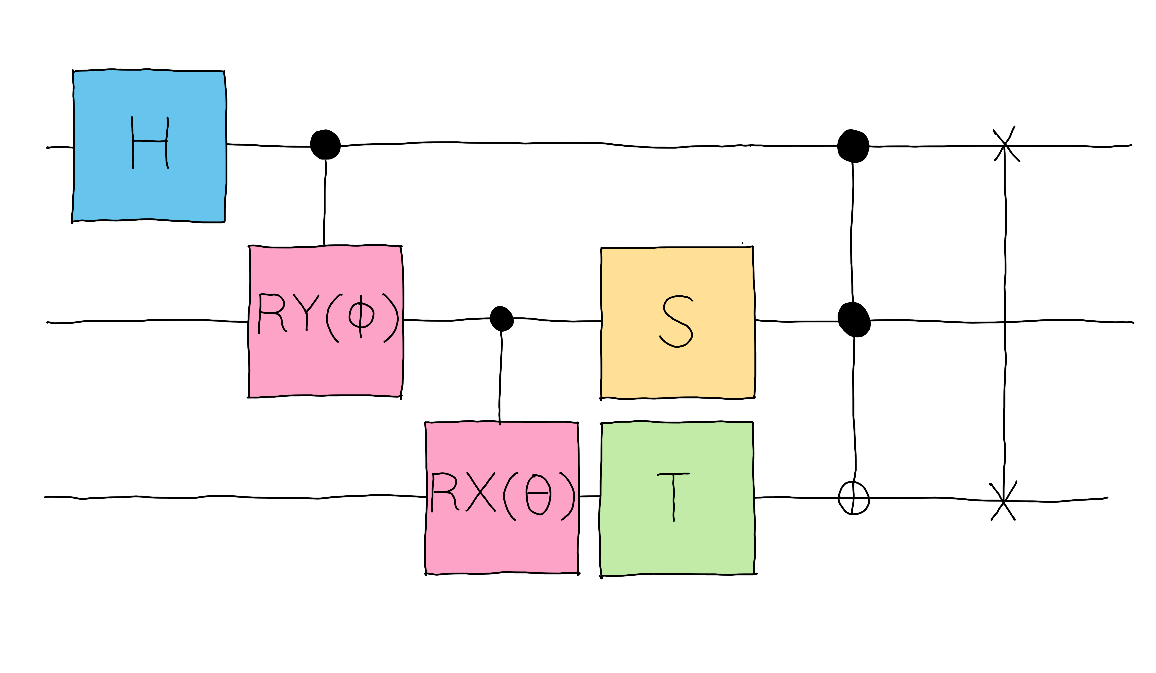
  <div style="color:#475569; font-size:14px; margin-top:8px;"><em>Target circuit for Exercise 0.</em></div>
</div>



In [ ]:
### Insert your code here!

dev = qml.device("default.qubit", wires = 3)


## Measurements

Measurements in PennyLane are special. They’re flexible, allowing you to perform measurements on simulators or actual quantum hardware–and they’re varied, allowing you to customize your quantum algorithms to your specific needs. Let’s look into different PennyLane measurements and how you can use them to your advantage.

In PennyLane, we implement measurement as follows:

In [ ]:
dev = qml.device("default.qubit", wires = 2)

@qml.set_shots(100)
@qml.qnode(dev)
def simple_circuit():
    qml.PauliX(1)
    return qml.counts(wires=[0, 1])  # Example; also try qml.counts() or qml.probs()

print(simple_circuit())

One could put one of the following Pennylane measurement in place of `qml.sample(wires=[0, 1])` in the block above.
*  `qml.sample()`: **For drawing samples** When running experiments on quantum device we often take samples. We specify a number of shots which indicates how many times we run the circuit and hence how many samples we obtain.
*  `qml.counts()`: **For taking counts** However, sometimes we have hundreds or thousands of shots, and we are likely only interested in the number of occurrences (or counts) for each possible measurement outcome. In this situation, use this.
*  `qml.probs()`: **For calculating probability distribution** Although we can obtain the probabilities of a specific observable with samples and counts, sometimes one need the exact measurement outcome probability distribution and in this case one can use this to calculate probabilities analytically.
*  `qml.expval()`: **For calculating expectation values** Expectation values are probably the most used type of measurement, especially for optimization and machine learning since they give useful information about the state and they’re differentiable.

For more details about Pennylane measurement, please see https://docs.pennylane.ai/en/stable/introduction/measurements.html.

---

<div style="background-color:#eff6ff; border:1px solid #93c5fd; border-left:7px solid #1d4ed8; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#1d4ed8; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 1  ·  EXERCISE 1</div>
  <h3 style="color:#172554; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Measurement outcomes</h3>
</div>

Create a circuit on two qubits in a linear array that flips qubit 0 and not qubit 1, and then try to measure them both with `qml.sample()`, `qml.counts()`, and `qml.probs()`.

What measurement outcome do you expect?

Simulate the circuit and see if the results match your expectations.

*Tip:* You might find the gate `qml.X` or `qml.PauliX` useful.


<div style="background-color:#f0fdf4; border:1px solid #86efac; border-left:7px solid #15803d; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#15803d; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 1  ·  EXERCISE 1</div>
  <h3 style="color:#14532d; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Example code</h3>
</div>

In [ ]:
### Insert your code here!


In [ ]:
### Insert your code here!


In [ ]:
### Insert your code here!


---

<div style="background-color:#eff6ff; border:1px solid #93c5fd; border-left:7px solid #1d4ed8; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#1d4ed8; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 1  ·  EXERCISE 2</div>
  <h3 style="color:#172554; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Expectation values</h3>
</div>

Create a circuit to prepare $|+\rangle^{\otimes 2}$, and then try to measure the expectation value of operator $X_0\otimes X_1$ and $Z_0\otimes Z_1$ using `qml.expval()`.


In [ ]:
dev = qml.device("default.qubit", wires = 2)
### Insert your code here!


In [ ]:
dev = qml.device("default.qubit", wires = 2)
### Insert your code here!

---

<div style="background-color:#eff6ff; border:1px solid #93c5fd; border-left:7px solid #1d4ed8; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#1d4ed8; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 1  ·  EXERCISE 3</div>
  <h3 style="color:#172554; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Bell-state preparation</h3>
</div>

Construct a circuit for preparing one of the Bell state $\frac{1}{\sqrt{2}}\left(|00\rangle+|11\rangle\right)$. Measure each qubit in the computational basis for 100 shots, and return the counts of 0 and 1 for each qubit respectively. First do it without `qml.counts()`.


In [ ]:
dev = qml.device("default.qubit", wires = 2)
### Insert your code here!



The above works, but the correlation information that characterise the Bell state is no longer present in the counts, as we do not see whether each 0 from the first wire corresponds to a 0 in the second. However, Pennylane does store this information. To recover it, we can use `qml.counts()` to see that there is no instances of '01' or '10' (Replace the measurement with `qml.counts()` in the circuit above).

In [ ]:
dev = qml.device("default.qubit", wires = 2)
### Insert your code here!


In Pennylane, we can also do the same with an observable specified. Try to measure $X_0 \otimes X_1$ using `qml.X` like before, we expect all outcomes to be 1, which indeed happens.

In [ ]:
dev = qml.device("default.qubit", wires = 2)
### Insert your code here!


In Pennylane, we can also return the quantum state in the computational basis using `qml.state()`. Try to return `qml.state()` using the same circuit as before. The returned array is in lexicographic order.

Recall that in the computational basis, the Bell state takes the form $\frac{1}{\sqrt{2}}\left(|00\rangle+|11\rangle\right)$.

In [ ]:
dev = qml.device("default.qubit", wires = 2)
### Insert your code here!

# Parametrizing a quantum circuit
In order to prove that our Bell state is a Bell state without cheating, we need to perform measurement in multiple bases. This is a great time to investigate parametrized quantum circuits.

A parametrized quantum circuit is one where one or more gates have free variables to be specified at run-time. This allows for a classical script to treat the call to a quantum computer as a black box with free input variables, and, for instance, optimize over the output. This is a key idea in NISQ algorithms, which you will encounter next week in the lecture and tutorial.

## Declaring a parametrized circuit as a function

To construct our parametrized circuit, we will define a quantum function which takes the parameters as an input, and returns the desired cost function.
We will construct a parametrized circuit that allows to measure the second qubit of the bell state we prepared above in an arbitrary basis (on the ZX plane), while the first one is always measured in the Z basis.

The gate that we are going to parameterize is a Y rotation on qubit 1
$$R_y(\theta) = e^{-i\theta/2 Y_1}=\left(\begin{array}{cc}\cos(\theta/2) & -\sin(\theta/2)\\ \sin(\theta/2) &\cos(\theta/2)\end{array} \right). $$
This rotates between the X and Z axis on qubit 1 as $\theta$ runs from $0\rightarrow\pi$, which means that at a measurement of the state $R_y(\theta)|\Psi\rangle$ in the Z (computational) basis is equivalent to a measurement of $|\Psi\rangle$ in the $\cos(\theta) Z - \sin(\theta) X$ basis. In most physical implementations of quantum devices, direct measurement along more than 1 axis is not possible, but the above is very cost-effective to implement.

In PennyLane, `qml.RY(theta, wires=1)` specifies both the rotation angle and the qubit on which the gate acts.

In [ ]:
dev = qml.device("default.qubit", wires = 2)

@qml.set_shots(100)
@qml.qnode(dev)
def circuit_bell_pqc(theta):
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0,1])
    qml.RY(theta, wires=1)
    return qml.counts()

## Visualizing the parametrized circuit

To visualize your circuit with Pennylane, we can define a *drawer* using `qml.draw()`. This module provides the circuit drawing functionality used to display circuits visually. For more information, check https://docs.pennylane.ai/en/stable/code/qml_drawer.html.

In [ ]:
qml.drawer.use_style("black_white")
qml.drawer.draw_mpl(circuit_bell_pqc, decimals=1)(0.5);

## Circuits as functions

In Pennylane, quantum circuits are used as mathematical models, or functions. This means we can get creative and do anything with quantum circuit we can usually only do with functions. Having defined the parametrized circuit as a function, we can directly call the function with a numeric parameter value.

In [ ]:
print('Bell state Phi+, 100 measurements in the Z0, Z1 basis:')
print(circuit_bell_pqc(theta=0))

print('Bell state Phi+, 100 measurements in the Z0, X1 basis:')
print(circuit_bell_pqc(theta=np.pi/2))

With theta set to $\pi/2$, we are measuring our Bell state in two uncorrelated bases, and we expect the results to be similarly uncorrelated.
To make a completely convincing proof, let us study the correlation between our measurements as we rotate $\theta$.

In [ ]:
dev = qml.device("default.qubit", wires = 2)

@qml.set_shots(100)
@qml.qnode(dev)
def circuit_bell_pqc(theta):
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0,1])
    qml.RY(theta, wires=1)
    return qml.sample()

def correlation_function(theta):
    samples = circuit_bell_pqc(theta)
    correlation = []
    for i in range(len(samples)):
        correlation.append( 1 - (samples[i][0] ^ samples[i][1]) )
        # Return 1 when the measurements of two qubits are the same, i.e. correlated measurement
    return {'0': correlation.count(0), '1': correlation.count(1) }

correlation_function(theta=np.pi/2) # Try different theta and see what happens

---

# Tutorial 2 — Exercises and Solutions

Answer the following questions. The first one requires no code, the second one you can use numpy, and for the third you can use PennyLane.

---

<div style="background-color:#eff6ff; border:1px solid #93c5fd; border-left:7px solid #1d4ed8; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#1d4ed8; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 2  ·  QUESTION 1</div>
  <h3 style="color:#172554; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Pauli-string decomposition</h3>
</div>

Write a Python script that accepts an $n$-qubit Hermitian matrix $H\in\mathrm{Herm}(\mathbb{C}^{2^n\times 2^n};\mathbb{R})$ and calculates its decomposition into Pauli strings,

$$
H=\sum_{k=1}^{4^n}w_k P_k,\qquad
P_k\in\{I,X,Y,Z\}^{\otimes n},\quad w_k\in\mathbb{R}.
$$

The single-qubit Pauli matrices are

$$
I=\begin{pmatrix}1&0\\0&1\end{pmatrix},\qquad
X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad
Y=\begin{pmatrix}0&-i\\i&0\end{pmatrix},\qquad
Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}.
$$

**Hints from the exercise sheet:** You do not have to check whether $H$ is Hermitian. With a fixed enumeration of the $4^n$ Pauli strings, the script can return the real-valued array of their coefficients.


In [ ]:
import numpy as np
from functools import reduce
import itertools

def pauli_matrices():
    pauli_I = np.eye(2)
    pauli_X = np.array([[0, 1], [1, 0]])
    pauli_Y = np.array([[0, -1j], [1j, 0]])
    pauli_Z = np.array([[1, 0], [0, -1]])

    return {'I': pauli_I, 'X': pauli_X, 'Y': pauli_Y, 'Z': pauli_Z}

def pauli_strings(n):
    pauli_operators = ['I', 'X', 'Y', 'Z']
    all_pauli_strings = [''.join(p) for p in itertools.product(pauli_operators, repeat=n)] #creates all pauli strings of length n
    return all_pauli_strings

def decompose_hermitian_matrix(H):
    ### Insert your code here!

    return np.array(coefficients)

In [ ]:
# Example: generate a random Hermitian two-qubit Hamiltonian and decompose it.
rng = np.random.default_rng(42)
n = 2  # Change the value of n as needed
H = np.random.random((2**n, 2**n)) + 1j * np.random.random((2**n, 2**n))
H = (H + H.conj().T) / 2  # Make H Hermitian

coefficients = decompose_hermitian_matrix(H)
print(coefficients)

---

<div style="background-color:#eff6ff; border:1px solid #93c5fd; border-left:7px solid #1d4ed8; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#1d4ed8; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 2  ·  QUESTION 2</div>
  <h3 style="color:#172554; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Variational quantum eigensolver (VQE)</h3>
</div>

Implement the following single-qubit VQE experiments in **PennyLane**.

#### Single-qubit VQE with brute-force grid search

1. Implement a Python function that generates the parametric circuit $U_3(\theta,\psi,\lambda)$. Do not use `qml.U3(theta, psi, lam, wires=0)`.
2. Use the function to:
   - prepare $|\psi(\theta,\psi,\lambda)\rangle=U_3(\theta,\psi,\lambda)|0\rangle$;
   - evaluate $\langle\psi(\theta,\psi,\lambda)|H|\psi(\theta,\psi,\lambda)\rangle$;
   - find optimal values of $\theta$, $\psi$, and $\lambda$ by brute-force grid search.
3. Test for $H\in\{I,X,Y,Z\}$, considering different parameter initializations (e.g., random values in their admissible ranges or zeros).




In [ ]:
import pennylane as qml
import numpy as np
from scipy.optimize import minimize

vqe_device = qml.device("default.qubit", wires=1)



def U3_circuit(theta, phi, lam):
    """Prepare the parametrized single-qubit circuit."""
    ### Insert your code here!


@qml.qnode(vqe_device)
def state_u3(params):
    """Return the two complex amplitudes of the prepared state."""
    ### Insert your code here!


@qml.qnode(vqe_device)
def energy_u3(params, hamiltonian):
    """Return <0|U3† H U3|0> as an exact expectation value."""
    ### Insert your code here!


hamiltonians = {
    "I": qml.I(0),
    "X": qml.X(0),
    "Y": qml.Y(0),
    "Z": qml.Z(0),
}

example_parameters = np.array([np.pi / 2, np.pi, 0.0])
qml.drawer.use_style("black_white")

print("U3 circuit:")
qml.draw_mpl(state_u3, decimals=2)(example_parameters)
plt.show()
print("Prepared state:", state_u3(example_parameters))
print("<X>:", float(energy_u3(example_parameters, hamiltonians["X"])))

#### Brute-force grid search

In [ ]:
def grid_search(hamiltonian, n_theta=9, n_psi=12, n_lambda=6):
    """Return (theta, psi, lambda) and minimum energy on a 3D angle grid."""
    theta_values = np.linspace(0.0, np.pi, n_theta)
    psi_values = np.linspace(0.0, 2 * np.pi, n_psi, endpoint=False)
    lambda_values = np.linspace(0.0, 2 * np.pi, n_lambda, endpoint=False)

    best_params, best_energy = None, np.inf
    for theta in theta_values:
        for psi in psi_values:
            for lam in lambda_values:
                params = np.array([theta, psi, lam], dtype=float)
                energy = float(energy_u3(params, hamiltonian))
                if energy < best_energy:
                    best_params, best_energy = params.copy(), energy
    return best_params, best_energy


print("Brute-force results:")
for name, hamiltonian in hamiltonians.items():
    params, minimum = grid_search(hamiltonian)
    print(f"H={name}: min <H> = {minimum:+.6f} at [theta, psi, lambda] = {np.round(params, 5)}")

---

<div style="background-color:#eff6ff; border:1px solid #93c5fd; border-left:7px solid #1d4ed8; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#1d4ed8; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 2  ·  QUESTION 3</div>
  <h3 style="color:#172554; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Parameter-shift rule</h3>
</div>

Let $G\in\mathrm{Herm}(\mathbb{C}^{2\times 2};\mathbb{R})$ have two distinct eigenvalues $e_0<e_1$, and let $a\in\mathbb{R}$ be a constant. Show that

$$
U=\frac{a}{r}(G-sI), \qquad
r=\frac{a}{2}(e_1-e_0), \qquad
s=\frac{1}{2}(e_1+e_0)
$$

is unitary. (As the expression contains $a/r$, assume $a\ne0$.)


<div style="background-color:#f0fdf4; border:1px solid #86efac; border-left:7px solid #15803d; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#15803d; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 2  ·  Answer 3</div>
  <h3 style="color:#14532d; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Proof</h3>
</div>
Type here


---

<div style="background-color:#eff6ff; border:1px solid #93c5fd; border-left:7px solid #1d4ed8; border-radius:10px; padding:15px 19px; margin:18px 0 16px 0;">
  <div style="color:#1d4ed8; font-weight:750; font-size:12px; letter-spacing:1px; margin-bottom:4px;">TUTORIAL 2  ·  QUESTION 4</div>
  <h3 style="color:#172554; font-weight:750; font-size:21px; line-height:1.35; margin:0;">Variational quantum eigensolver (VQE)</h3>
</div>

#### Single-qubit VQE with gradient-based optimization

1. Compute the gradients of the $U_3(\theta,\psi,\lambda)$ ansatz with respect to each angle using the **parameter-shift rule**.
2. Replace grid search by a gradient-based optimizer, such as SGD or (L)-BFGS.
3. Test for $H\in\{I,X,Y,Z\}$ and compare zero and random initializations.

#### Parameter-shift gradients and L-BFGS-B

For each angle $x\in\{\theta,\psi,\lambda\}$ of `U3`, the parameter-shift rule for the expectation value $E$ gives

$$\frac{\partial E}{\partial x}=
\frac{E(x+\pi/2)-E(x-\pi/2)}{2}.$$

The following code evaluates this rule explicitly, then supplies the gradient to SciPy's L-BFGS-B optimizer.

In [ ]:
def parameter_shift_gradient(params, hamiltonian, shift=np.pi / 2):
    """Parameter-shift gradient w.r.t. theta, psi, and lambda."""
    ### Insert your code here!


def optimize_vqe(hamiltonian, initial_params):
    """Minimize the energy using the explicitly parameter-shifted Jacobian."""
    result = minimize(
        fun=lambda params: float(energy_u3(params, hamiltonian)),
        x0=np.asarray(initial_params, dtype=float),
        jac=lambda params: parameter_shift_gradient(params, hamiltonian),
        method="L-BFGS-B",
        bounds=[(0, np.pi), (0, 2 * np.pi), (0, 2 * np.pi)],
        options={"maxiter": 300, "ftol": 1e-12},
    )
    return result


In [ ]:
# Compare starting from all zeros with a random initialization.
# One angle (lambda) only changes the global phase of U3|0>, so energies
# are independent of lambda; for some Hamiltonians the zero start is stationary.
rng = np.random.default_rng(2026)

for name, hamiltonian in hamiltonians.items():
    initializations = {
        "zeros": np.zeros(3),
        "random": np.array([
            rng.uniform(0, np.pi),
            rng.uniform(0, 2 * np.pi),
            rng.uniform(0, 2 * np.pi),
        ]),
    }
    print(f"\nHamiltonian {name}: expected ground energy = {np.linalg.eigvalsh(qml.matrix(hamiltonian)).min():+.6f}")
    for label, start in initializations.items():
        result = optimize_vqe(hamiltonian, start)
        print(
            f"  {label:6s} -> min <H> = {result.fun:+.6f}; "
            f"angles = {np.round(result.x, 5)}; success={result.success}"
        )

print("\nNote: zero initialization may be stationary without being optimal (e.g. H=Z).")